# Binomial Distribution & Normal Distribution
姓名：＿＿＿＿　學號：＿＿＿＿

## 作業目標
依照課堂紅筆指定的 X ~ B(60, 0.26)，畫出二項分布，再疊上具有相同平均數與變異數的常態分布，觀察近似情形。

使用的參數為 n = 60、p = 0.26；投影片原本印刷的 B(40, 0.4) 是示範，不是本次使用的參數。

## 執行方式
使用具有 NumPy、Matplotlib 與 ipykernel 的 Python 核心，選擇 Restart Kernel and Run All，執行後儲存。本檔不需外部資料，也不使用隨機抽樣。
若缺少套件，可取消下一格的註解執行，安裝後重新啟動核心。

In [1]:
# %pip install numpy matplotlib ipykernel

## 1. 設定參數與計算常態分布參數
二項分布的平均數 μ = np，變異數 σ² = np(1 − p)，標準差 σ = √[np(1 − p)]。

依老師的近似條件檢查 np ≥ 5 及 n(1 − p) ≥ 5。這是判斷是否適合使用常態近似的經驗準則，不表示兩者完全相同。

In [2]:
from pathlib import Path
from math import comb
import numpy as np
import matplotlib.pyplot as plt

n = 60
p = 0.26
mu = n * p
variance = n * p * (1 - p)
sigma = np.sqrt(variance)

print(f'n = {n}, p = {p}')
print(f'平均數 μ = np = {mu:.4f}')
print(f'變異數 σ² = np(1-p) = {variance:.4f}')
print(f'標準差 σ = sqrt(np(1-p)) = {sigma:.4f}')
print(f'np = {n*p:.4f} ≥ 5：{n*p >= 5}')
print(f'n(1-p) = {n*(1-p):.4f} ≥ 5：{n*(1-p) >= 5}')
print(f'對應常態分布：μ = {mu:.4f}, σ = {sigma:.4f}')

n = 60, p = 0.26
平均數 μ = np = 15.6000
變異數 σ² = np(1-p) = 11.5440
標準差 σ = sqrt(np(1-p)) = 3.3976
np = 15.6000 ≥ 5：True
n(1-p) = 44.4000 ≥ 5：True
對應常態分布：μ = 15.6000, σ = 3.3976


本題結果為 μ = 15.6、σ² = 11.544、σ ≈ 3.3976。

老師投影片以 N(平均數, 標準差) 表示，因此對應 N(15.6, 3.3976)。
若以 N(平均數, 變異數) 表示，則為 N(15.6, 11.544)。以下圖例直接標出 μ 和 σ，避免混淆。

## 2. 計算二項機率與常態機率密度
- 二項分布：P(X = k) = C(n, k) × pᵏ × (1 − p)ⁿ⁻ᵏ，k = 0, 1, …, n。
- 常態分布：f(x) = exp[−(x − μ)² / (2σ²)] / [σ√(2π)]。

二項分布的每根直線高度是單點機率；常態曲線的高度是機率密度。疊圖可用來比較形狀，但常態分布的機率需由區間面積取得，曲線高度不是單點機率。

In [3]:
# 每個可能成功次數的精確二項機率
k = np.arange(n + 1)
binomial_pmf = np.array([
    comb(n, int(ki)) * p**int(ki) * (1 - p)**(n - int(ki))
    for ki in k
])

# 使用密集且連續的橫軸座標畫常態曲線
x = np.linspace(0, n, 2401)
normal_pdf = (
    np.exp(-0.5 * ((x - mu) / sigma)**2)
    / (sigma * np.sqrt(2 * np.pi))
)

# 核對機率總和，以及二項機率所算出的平均數、變異數
np.testing.assert_allclose(binomial_pmf.sum(), 1.0, atol=1e-12)
np.testing.assert_allclose(np.sum(k * binomial_pmf), mu, atol=1e-12)
np.testing.assert_allclose(
    np.sum((k - mu)**2 * binomial_pmf), variance, atol=1e-12
)
assert np.all(binomial_pmf >= 0)
assert np.all(normal_pdf >= 0)

print(f'二項機率總和 = {binomial_pmf.sum():.12f}')
print(f'機率最大的成功次數 = {k[np.argmax(binomial_pmf)]}')
print('檢查通過：機率總和、平均數與變異數均正確。')

二項機率總和 = 1.000000000000
機率最大的成功次數 = 15
檢查通過：機率總和、平均數與變異數均正確。


## 3. 疊合比較圖
紅色空心點與垂直線表示二項分布，藍色曲線表示對應常態分布，配色依課堂範例。
左圖放大主要機率區域以便比較；右圖完整呈現 k = 0 到 60 的範圍。

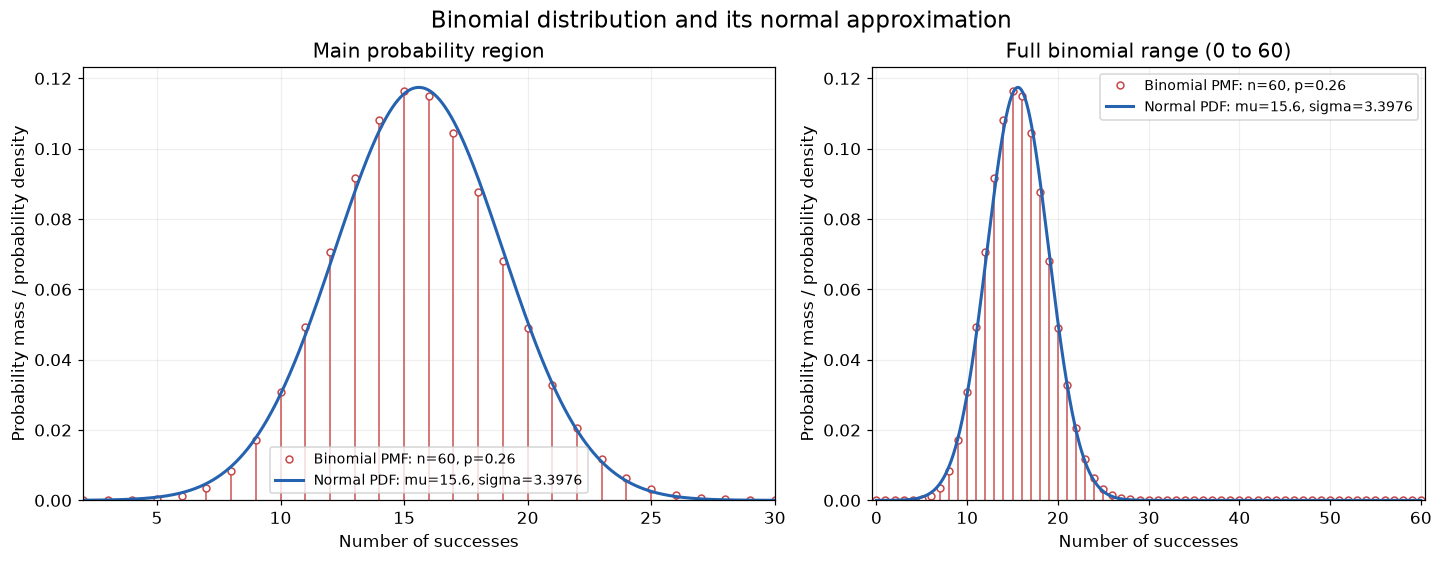

已儲存圖檔： D:\Project\Python-ML-Projects-2026\NFU\Binomial_Normal\binomial_normal_comparison.png


In [4]:
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110})

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), constrained_layout=True,
    gridspec_kw={'width_ratios': [1.25, 1]}
)
for ax in axes:
    ax.vlines(k, 0, binomial_pmf, color='#c74747', linewidth=1.1, alpha=0.85)
    ax.plot(
        k, binomial_pmf, 'o', color='#c74747',
        markerfacecolor='white', markersize=4.5,
        label=f'Binomial PMF: n={n}, p={p}'
    )
    ax.plot(
        x, normal_pdf, color='#2563b0', linewidth=2,
        label=f'Normal PDF: mu={mu:.1f}, sigma={sigma:.4f}'
    )
    ax.set_xlabel('Number of successes')
    ax.set_ylabel('Probability mass / probability density')
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

axes[0].set_xlim(max(0, np.floor(mu - 4*sigma)), min(n, np.ceil(mu + 4*sigma)))
axes[0].set_title('Main probability region')
axes[1].set_xlim(-0.5, n + 0.5)
axes[1].set_title('Full binomial range (0 to 60)')
fig.suptitle('Binomial distribution and its normal approximation', fontsize=15)

# 從 NFU 根目錄或 Notebook 所在目錄執行，皆將圖檔存於作業資料夾
output_dir = Path('Binomial_Normal') if Path('Binomial_Normal/python.ipynb').is_file() else Path('.')
output_file = output_dir / 'binomial_normal_comparison.png'
fig.savefig(output_file, dpi=180)
plt.show()
plt.close(fig)
print('已儲存圖檔：', output_file.resolve())

## 4. 結果說明
本題二項分布為 B(60, 0.26)，平均數為 15.6，變異數為 11.544，標準差約為 3.3976。
由於 np = 15.6 ≥ 5 且 n(1 − p) = 44.4 ≥ 5，符合課堂所列的常態近似條件。

從疊圖可見，兩種分布的中心位置與分散程度接近，但並未完全重合。二項分布因 p < 0.5 而略向右偏，常態分布則以平均數為中心左右對稱。

二項分布是離散分布，只在整數成功次數上有機率；常態分布是連續分布，以曲線下的面積表示區間機率。本作業比較的是分布形狀，沒有要求計算特定區間機率。若後續要用常態分布近似 P(X = k)，可計算 k − 0.5 至 k + 0.5 的常態曲線下面積，進行連續性修正。

## 繳交前檢查
1. 補上姓名、學號。
2. 重新執行所有儲存格，確認參數與比較圖都正常顯示，再儲存本 Notebook。
3. 依老師繳交規定上傳 Notebook；另附圖檔可方便檢視。

題目依據：課堂照片紅筆標示的「plot the binomial distribution，X ~ B(60, 0.26)」與「plot the corresponding normal distribution」。